## random imputation for numerical data

In [1]:
import numpy as np
import pandas as pd 
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [3]:
df.isnull().mean()

Survived    0.000000
Age         0.198653
Fare        0.000000
dtype: float64

In [4]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [5]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [6]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [8]:
X_train.tail()

,Age,Fare,Age_imputed
534,30.0,8.6625,30.0
584,NaN,8.7125,NaN
493,71.0,49.5042,71.0
527,NaN,221.7792,NaN
168,NaN,25.9250,NaN


In [10]:
# Fix for X_train
X_train.loc[X_train['Age_imputed'].isnull(), 'Age_imputed'] = (
    X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
)

# Fix for X_test
X_test.loc[X_test['Age_imputed'].isnull(), 'Age_imputed'] = (
    X_train['Age'].dropna().sample(X_test['Age'].isnull().sum()).values
)

In [11]:
X_train.tail()

,Age,Fare,Age_imputed
534,30.0,8.6625,30.0
584,NaN,8.7125,4.0
493,71.0,49.5042,71.0
527,NaN,221.7792,23.0
168,NaN,25.9250,31.0


In [12]:
X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

array([26.  , 50.  , 25.  , 58.  , 30.  , 29.  ,  4.  , 48.  , 40.  ,
       23.  , 27.  , 48.  , 59.  ,  3.  , 24.  , 27.  , 21.  , 18.  ,
        8.  , 13.  , 21.  , 34.  , 60.  , 31.  ,  4.  , 35.  , 32.  ,
       11.  , 32.  , 51.  , 19.  , 29.  , 25.  , 19.  , 42.  , 52.  ,
       31.  , 28.  , 27.  , 45.  , 53.  , 19.  , 29.  , 29.  , 24.  ,
        6.  ,  7.  , 26.  , 29.  , 33.  , 17.  , 46.  , 33.  , 31.  ,
       39.  , 21.  , 16.  , 21.  , 51.  , 34.5 ,  9.  ,  9.  , 34.  ,
        0.83, 50.  , 51.  , 38.  , 16.  , 35.  , 37.  , 20.  , 21.  ,
       63.  , 28.  ,  4.  , 27.  , 62.  , 42.  , 21.  , 34.  , 42.  ,
       23.  , 18.  , 31.  , 20.  , 20.  , 16.  , 25.  , 58.  , 32.  ,
       19.  , 39.  , 32.  , 20.  , 30.  , 22.  , 47.  , 38.  , 18.  ,
       58.  , 24.  , 66.  , 34.  , 38.  , 21.  , 39.  , 25.  , 16.  ,
       24.  , 22.  ,  2.  , 44.  , 40.  , 28.  , 45.  , 28.  , 33.  ,
       24.  ,  2.  ,  1.  , 36.  , 22.  , 41.  , 54.  , 31.  , 32.  ,
       45.  , 36.  ,

In [13]:
X_train['Age'].isnull().sum()

np.int64(148)

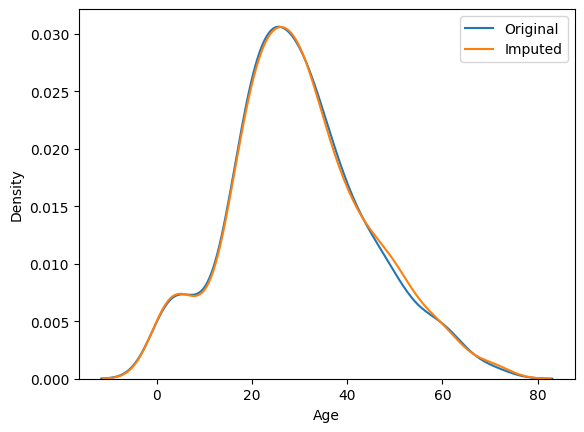

In [15]:
sns.kdeplot(X_train['Age'], label='Original')
sns.kdeplot(X_train['Age_imputed'], label='Imputed')
plt.legend()
plt.show()

In [16]:
print('Original variable variance: ', X_train['Age'].var())
print('Variance after random imputation: ', X_train['Age_imputed'].var())Random_imputation.ipynb

Original variable variance:  204.34951339046142
Variance after random imputation:  210.06568087023345


In [18]:
X_train.cov()

,Age,Fare,Age_imputed
Age,204.349513,71.512440,204.349513
Fare,71.512440,2368.246832,50.464708
Age_imputed,204.349513,50.464708,210.065681


<Axes: >

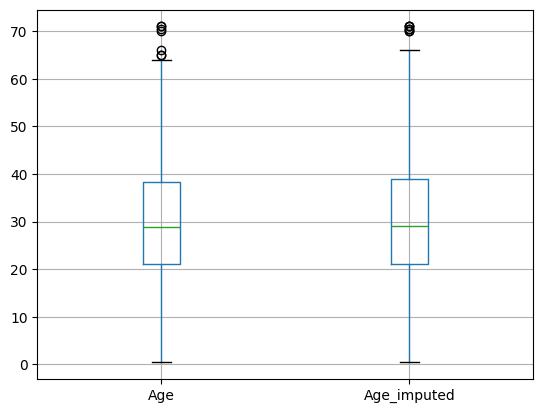

In [19]:
X_train[['Age', 'Age_imputed']].boxplot()

## random imputation for cateogorical data

In [21]:
data = pd.read_csv('train_data.csv',usecols=['GarageQual','FireplaceQu', 'SalePrice'])

In [22]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [23]:
data.isnull().mean() * 100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [28]:
X = data.drop(columns=['SalePrice'])
y = data['SalePrice']

In [29]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [30]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [31]:
X_train.head()

,FireplaceQu,GarageQual,GarageQual_imputed,FireplaceQu_imputed
455,TA,TA,TA,TA
863,NaN,TA,TA,NaN
504,Fa,TA,TA,Fa
1413,Gd,TA,TA,Gd
1389,Gd,TA,TA,Gd


In [32]:
X_train.loc[X_train['GarageQual_imputed'].isnull(),'GarageQual_imputed'] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isnull().sum()).values
X_test.loc[X_test['GarageQual_imputed'].isnull(),'GarageQual_imputed'] = X_train['GarageQual'].dropna().sample(X_test['GarageQual'].isnull().sum()).values

X_train.loc[X_train['FireplaceQu_imputed'].isnull(),'FireplaceQu_imputed'] = X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu'].isnull().sum()).values
X_test.loc[X_test['FireplaceQu_imputed'].isnull(),'FireplaceQu_imputed'] = X_train['FireplaceQu'].dropna().sample(X_test['FireplaceQu'].isnull().sum()).values

In [33]:
X_train.head()

,FireplaceQu,GarageQual,GarageQual_imputed,FireplaceQu_imputed
455,TA,TA,TA,TA
863,NaN,TA,TA,Fa
504,Fa,TA,TA,Fa
1413,Gd,TA,TA,Gd
1389,Gd,TA,TA,Gd


In [34]:
temp = pd.concat(
        [
            X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()),
            X_train['GarageQual_imputed'].value_counts() / len(X_train)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

In [35]:
temp

,original,imputed
TA,0.951043,0.952055
Fa,0.037171,0.036815
Gd,0.009973,0.009418
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [36]:
temp2 = pd.concat(
        [
            X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()),
            X_train['FireplaceQu_imputed'].value_counts() / len(df)
        ],
        axis=1)

temp2.columns = ['original', 'imputed']

temp2

,original,imputed
Gd,0.494272,0.648709
TA,0.412439,0.542088
Fa,0.040917,0.053872
Po,0.027823,0.033670
Ex,0.024550,0.032548


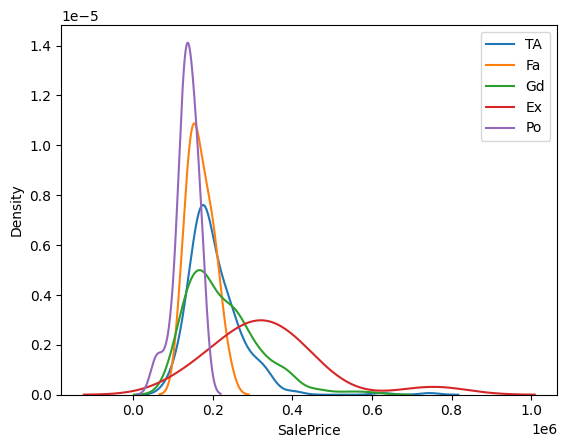

In [39]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.kdeplot(y_train[X_train['FireplaceQu'] == category], label=category)

plt.legend()
plt.show()

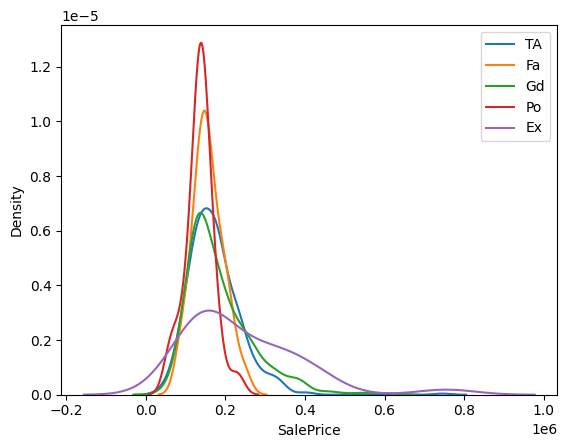

In [40]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.kdeplot(y_train[X_train['FireplaceQu_imputed'] == category], label=category)

plt.legend()
plt.show()